# Phase 1 - Convolutional Neural Networks

Please follow the notebook in order. Make sure to add code where indicated by `''' TODO '''` or `# YOUR CODE HERE`. Please answer all questions indicated with '❓', and answer where it says 'ANSWER HERE'.

Ensure your notebook is easy to follow. All written report answers should be provided in the notebook itself.

Section 5 asks you to run different hyperparameters- please make sure to run all your codes and make sure outputs are neat enough to read.

You may find [this](https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) Pytorch tutorial helpful.

## **Overview**
1. Loading & Visualizing Data
2. Utility Functions
3. Define CNNs
4. Train and Evaluate
5. Experiments and Reporting

In [1]:
import time, random
import torch
import torch.nn as nn
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


# **1. Loading & Visualizing Data**

Please use MNIST for this phase. MNIST is a digit classification dataset, with greyscale 28x28 images, and 10 classes (numbers 0-9).

See [documentation.](https://pytorch.org/vision/0.15/generated/torchvision.datasets.MNIST.html) You can also see the `MNIST_Tutorial.ipynb`.

Please complete loading the data below.

Please also complete `show_imgs()`. Function should input the dataloader, and show 10 random images and their labels.

In [2]:
train_data = datasets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.MNIST(root='./data', train=False, download=True, transform=transforms.ToTensor())
batch_size = 32
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=0)
print('Train:',len(train_data),'Test:',len(test_data))

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 338kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.21MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.2MB/s]

Train: 60000 Test: 10000


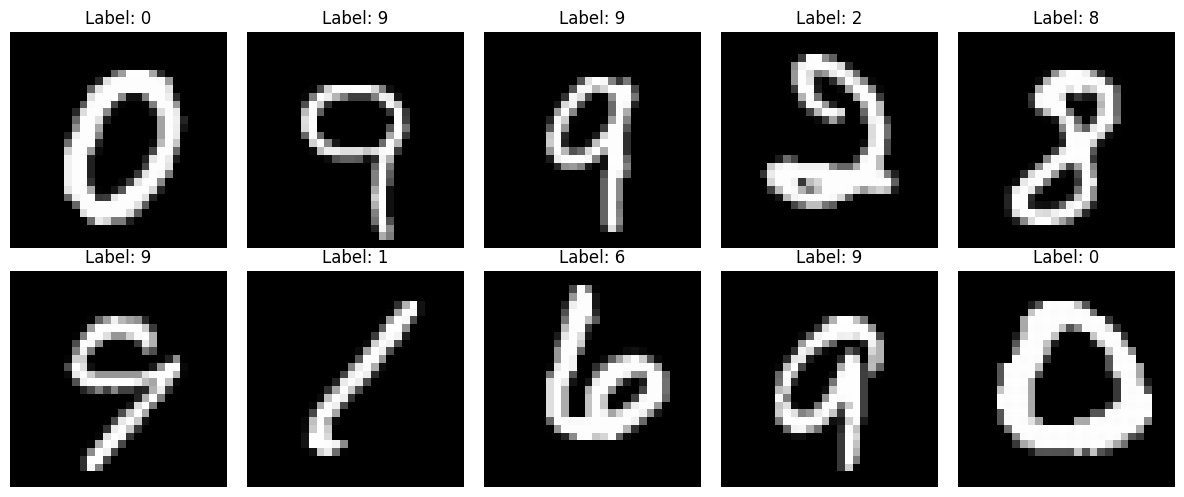

In [3]:
def show_imgs(dataloader, n=10):
    images, labels = next(iter(dataloader))
    chosen = torch.randperm(len(images))[:min(n,len(images))]
    fig, axes = plt.subplots(2, 5, figsize=(12,5))
    for ax, idx in zip(axes.flat, chosen):
        ax.imshow(images[idx].squeeze().cpu(), cmap='gray')
        ax.set_title(f'Label: {labels[idx].item()}'); ax.axis('off')
    plt.tight_layout(); plt.show()
show_imgs(train_loader)

## **2. Utility Functions**

Please complete `train()` and `plot_learning_curves()` functions. `test_accuracy()` has already been provided to you.

In [4]:
@torch.no_grad()
def test_accuracy(model, test_loader, input_size=None, device=device):
    model.to(device); model.eval()
    correct = total = 0
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    accuracy = correct / max(total,1)
    print(f'Test accuracy: {accuracy:.2%}')
    return accuracy

## **2.1 Train Function**
Please refer to the train function in `MNIST_Classifier.ipynb` to complete this function.
- You will need to store the loss and accuracies per iteration (to plot later). Do this for both the train set and test set!
- Please print the loss, accuracy and time taken **each epoch** for both train and test sets

In [5]:
def train(model, loss_fn, optimizer, train_loader, test_loader, batch_size, num_epochs, device):
    """Return epoch histories (train/test loss and accuracy)."""
    model.to(device)
    history = {k: [] for k in ('train_loss','train_acc','test_loss','test_acc')}
    for epoch in range(num_epochs):
        started=time.perf_counter()
        model.train(); running_loss=correct=total=0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = loss_fn(outputs,labels)
            loss.backward(); optimizer.step()
            running_loss += loss.item()*labels.size(0)
            correct += (outputs.argmax(1)==labels).sum().item()
            total += labels.size(0)
        history['train_loss'].append(running_loss/max(total,1))
        history['train_acc'].append(correct/max(total,1))
        model.eval(); running_loss=correct=total=0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss=loss_fn(outputs,labels)
                running_loss += loss.item()*labels.size(0)
                correct += (outputs.argmax(1)==labels).sum().item()
                total += labels.size(0)
        history['test_loss'].append(running_loss/max(total,1))
        history['test_acc'].append(correct/max(total,1))
        print(f'Epoch {epoch+1:02d}/{num_epochs}: train loss={history["train_loss"][-1]:.4f}, '
              f'train acc={history["train_acc"][-1]:.2%}; test loss={history["test_loss"][-1]:.4f}, '
              f'test acc={history["test_acc"][-1]:.2%}; {time.perf_counter()-started:.1f}s')
    return history

## **2.2 Plot Learning Curves Function**
Plot the loss and accuracies from training. Example outputs will be provided in lab walkthrough.

In [6]:
def plot_learning_curve(history, title='Learning curves'):
    epochs=np.arange(1,len(history['train_loss'])+1)
    fig,ax=plt.subplots(1,2,figsize=(12,4))
    for split in ('train','test'):
        ax[0].plot(epochs,history[f'{split}_loss'],marker='o',label=split)
        ax[1].plot(epochs,history[f'{split}_acc'],marker='o',label=split)
    ax[0].set(title='Cross-entropy loss',xlabel='Epoch',ylabel='Loss')
    ax[1].set(title='Accuracy',xlabel='Epoch',ylabel='Accuracy',ylim=(0,1))
    for a in ax: a.grid(alpha=.2); a.legend()
    fig.suptitle(title); plt.tight_layout();plt.show()

# **3. Define CNNs**

A 1-Layer Architecture is already defined for you (`Net`) as a reference. Please complete the definitions of the 2-Layer CNN (`Net2`). The network architecture definitions are provided to you. You must calculate some dimensions yourself.

**NOTE:** For now, please use ReLU activation. You will experiment with other activations in Section 5.

In [7]:
class Net(nn.Module):
    def __init__(self, input_size=784, num_classes=10):
        super().__init__()
        self.layers=nn.Sequential(nn.Flatten(),nn.Linear(input_size,500),nn.ReLU(),nn.Linear(500,num_classes))
    def forward(self,x): return self.layers(x)

## **3.1 Create a 2-Layer CNN**
Complete `Net2` class.

 Network Architecture:
* ***Layer 1 (Input)***: Convolutional; input channel = 1, output channel = 20, kernel size = 3, step size = 1.
* ***Layer 2 (Output)***: Fully connected; input dimension = < you find out >, output dimension = < you find out >.

In [8]:
class Net2(nn.Module):
    """28x28 -> conv3/no padding -> 20x26x26 -> 10 logits."""
    def __init__(self, num_classes=10, activation='relu'):
        super().__init__()
        self.conv=nn.Conv2d(1,20,kernel_size=3,stride=1)
        self.activation=nn.ReLU() if activation=='relu' else nn.Tanh()
        self.fc=nn.Linear(20*26*26,num_classes)
    def forward(self,x):
        x=self.activation(self.conv(x))
        return self.fc(torch.flatten(x,1))

# **4. Train and Evaluate**

## **4.1 Training and Evaluating 1-Layer CNN**

Here, you must test your utility functions (`train()` and `plot_learning_curves()`)with the 1-Layer Model. Please at this stage ensure your utility functions are working correctly. The TAs will provide sample outputs in lab walkthrough.

**NOTE**: You can repeatedly use this below code block in Section 5 to run experiments, while making changes to the hyperparameters as required.

Epoch 01/10: train loss=0.2459, train acc=92.84%; test loss=0.1993, test acc=94.54%; 15.8s
Epoch 02/10: train loss=0.1657, train acc=95.61%; test loss=0.1618, test acc=95.89%; 12.8s
Epoch 03/10: train loss=0.1430, train acc=96.30%; test loss=0.1665, test acc=96.22%; 11.6s
Epoch 04/10: train loss=0.1348, train acc=96.59%; test loss=0.1796, test acc=95.70%; 11.5s
Epoch 05/10: train loss=0.1226, train acc=96.93%; test loss=0.1613, test acc=96.36%; 11.6s
Epoch 06/10: train loss=0.1185, train acc=97.10%; test loss=0.2175, test acc=96.28%; 11.7s
Epoch 07/10: train loss=0.1107, train acc=97.34%; test loss=0.1987, test acc=96.28%; 11.7s
Epoch 08/10: train loss=0.1075, train acc=97.41%; test loss=0.2315, test acc=96.25%; 11.4s
Epoch 09/10: train loss=0.0986, train acc=97.77%; test loss=0.2501, test acc=96.43%; 11.4s
Epoch 10/10: train loss=0.1069, train acc=97.67%; test loss=0.2622, test acc=95.61%; 11.6s


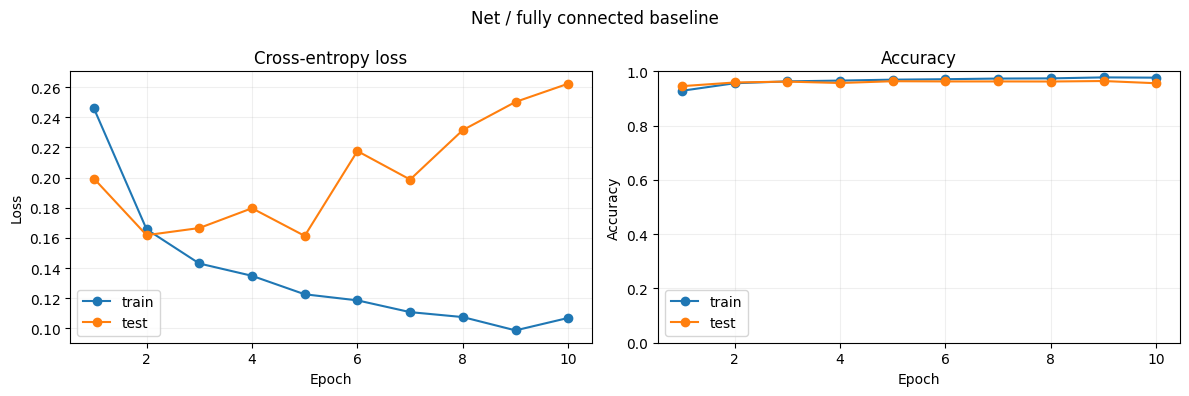

Test accuracy: 95.61%


0.9561

In [9]:
input_size=28*28
num_classes=10
lr=0.01
num_epochs=10
net=Net(input_size,num_classes).to(device)
loss_function=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(net.parameters(),lr=lr)
history_net=train(net,loss_function,optimizer,train_loader,test_loader,batch_size,num_epochs,device)
plot_learning_curve(history_net,'Net / fully connected baseline')
test_accuracy(net,test_loader,input_size,device)

## **4.2 Training and Evaluating 2-Layer CNN**


Please also train your 2-Layer network to ensure it is working properly.

Epoch 01/10: train loss=0.2326, train acc=94.53%; test loss=0.0887, test acc=97.26%; 14.4s
Epoch 02/10: train loss=0.0824, train acc=97.47%; test loss=0.0826, test acc=97.36%; 11.4s
Epoch 03/10: train loss=0.0579, train acc=98.21%; test loss=0.0895, test acc=97.39%; 11.4s
Epoch 04/10: train loss=0.0431, train acc=98.66%; test loss=0.0956, test acc=97.48%; 11.7s
Epoch 05/10: train loss=0.0403, train acc=98.75%; test loss=0.1174, test acc=97.27%; 11.7s
Epoch 06/10: train loss=0.0298, train acc=99.10%; test loss=0.1524, test acc=97.39%; 12.0s
Epoch 07/10: train loss=0.0272, train acc=99.19%; test loss=0.1275, test acc=97.34%; 12.6s
Epoch 08/10: train loss=0.0240, train acc=99.31%; test loss=0.1792, test acc=97.10%; 11.9s
Epoch 09/10: train loss=0.0228, train acc=99.39%; test loss=0.2056, test acc=97.06%; 11.6s
Epoch 10/10: train loss=0.0204, train acc=99.43%; test loss=0.2423, test acc=97.40%; 11.3s


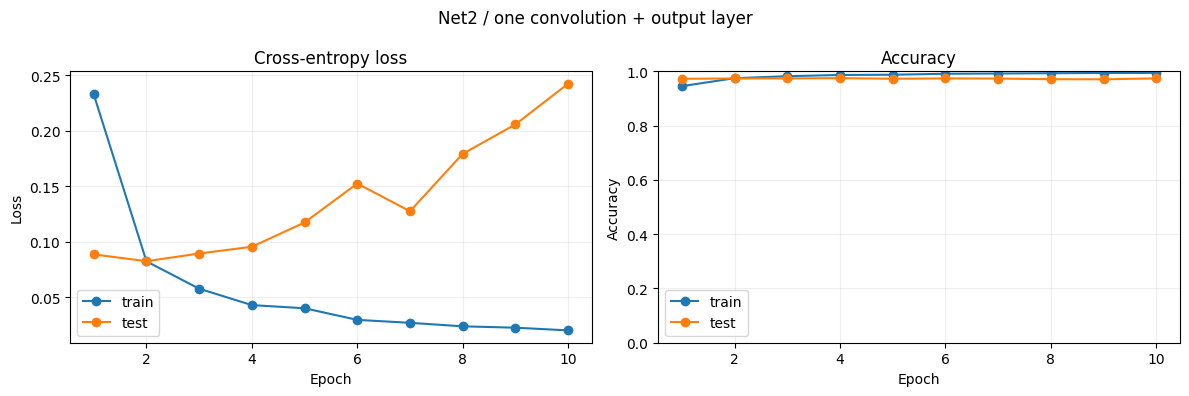

Test accuracy: 97.40%


0.974

In [10]:
input_size=28*28
num_classes=10
lr=0.01
num_epochs=10
net=Net2(num_classes).to(device)
loss_function=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(net.parameters(),lr=lr)
history_net2=train(net,loss_function,optimizer,train_loader,test_loader,batch_size,num_epochs,device)
plot_learning_curve(history_net2,'Net2 / one convolution + output layer')
test_accuracy(net,test_loader,input_size,device)

# **5. Experiments and Reporting**

In this section, you'll use the utility functions and model definitions from earlier to test various scenarios. You'll modify hyperparameters, run training, plot results, and analyze performance. Based on your observations, you'll answer specific questions.

Use the provided loss, accuracy, and learning curves to address the report questions for each subsection.

**Note:** You will primarily reuse functions from earlier sections. Make any necessary code changes in the sections marked `# YOUR CODE HERE`.

## **5.1 Learning Curves**

### **❓ Q 5.1.1 What is a Learning curve and why is it useful? You can refer to learning curves you have plotted in Section 4.** (you do not need to run any codes here)

**Answer:** A learning curve graphs training and validation/test loss or accuracy against training time (epochs). It shows how quickly the model converges, whether it generalizes, and whether additional training helps. High training and validation loss indicates underfitting; training loss falling while validation loss rises suggests overfitting. The actual results are displayed above when training completes.

---

### **5.2 Learning Rates**

Please plot the curves for three separate training instances with learning rates of: `2e-3`, `3e-4`, `5e-2 `

Use the 2-Layer CNN.

Epoch 01/10: train loss=0.2002, train acc=94.15%; test loss=0.0847, test acc=97.38%; 9.3s
Epoch 02/10: train loss=0.0727, train acc=97.80%; test loss=0.0708, test acc=97.71%; 9.7s
Epoch 03/10: train loss=0.0501, train acc=98.44%; test loss=0.0664, test acc=98.00%; 9.4s
Epoch 04/10: train loss=0.0377, train acc=98.80%; test loss=0.0685, test acc=97.98%; 9.6s
Epoch 05/10: train loss=0.0270, train acc=99.13%; test loss=0.0638, test acc=98.05%; 9.7s
Epoch 06/10: train loss=0.0229, train acc=99.27%; test loss=0.0777, test acc=97.67%; 9.5s
Epoch 07/10: train loss=0.0171, train acc=99.46%; test loss=0.0762, test acc=98.04%; 9.5s
Epoch 08/10: train loss=0.0116, train acc=99.66%; test loss=0.0765, test acc=98.00%; 9.7s
Epoch 09/10: train loss=0.0103, train acc=99.66%; test loss=0.0793, test acc=98.14%; 9.5s
Epoch 10/10: train loss=0.0087, train acc=99.73%; test loss=0.0847, test acc=97.89%; 9.6s


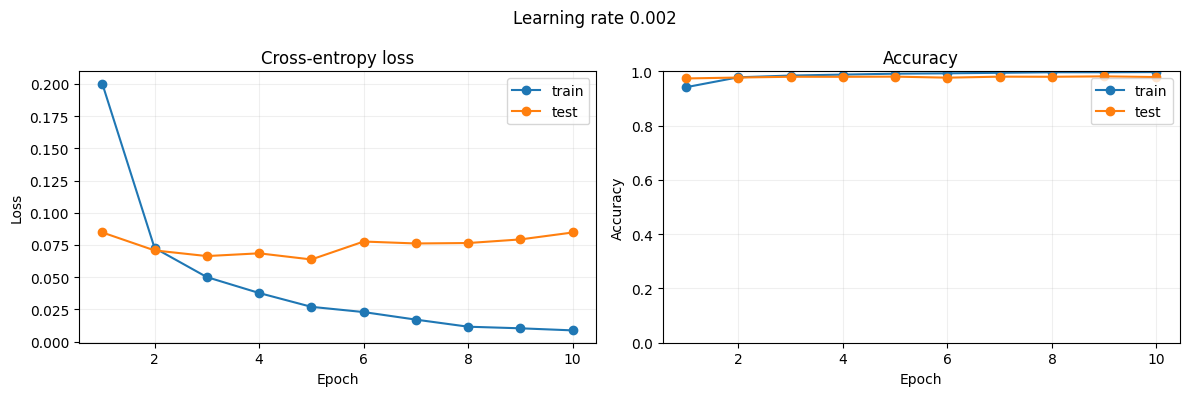

Learning rate 0.002: final train=99.73%, test=97.89%


In [11]:
# Reusable fair-comparison helper: fresh model/optimizer for each run.
def run_experiment(name, model_factory=Net2, lr=0.002, optimizer_type='adam',
                   momentum=0., weight_init=None, batch_size_exp=64, epochs=10):
    torch.manual_seed(SEED)
    model=model_factory().to(device)
    if weight_init is not None:
        with torch.no_grad():
            for module in model.modules():
                if isinstance(module,(nn.Conv2d,nn.Linear)):
                    if weight_init=='zeros': nn.init.zeros_(module.weight)
                    elif weight_init=='ones': nn.init.ones_(module.weight)
                    elif weight_init=='normal': nn.init.normal_(module.weight,mean=0,std=0.02)
                    if module.bias is not None: nn.init.zeros_(module.bias)
    opt=(torch.optim.Adam(model.parameters(),lr=lr) if optimizer_type=='adam'
         else torch.optim.SGD(model.parameters(),lr=lr,momentum=momentum))
    loader=DataLoader(train_data,batch_size=batch_size_exp,shuffle=True,num_workers=0)
    valid=DataLoader(test_data,batch_size=batch_size_exp,shuffle=False,num_workers=0)
    h=train(model,nn.CrossEntropyLoss(),opt,loader,valid,batch_size_exp,epochs,device)
    plot_learning_curve(h,name)
    print(f'{name}: final train={h["train_acc"][-1]:.2%}, test={h["test_acc"][-1]:.2%}')
    return h
history_lr_2e3=run_experiment('Learning rate 0.002',lr=2e-3)

Epoch 01/10: train loss=0.3689, train acc=90.19%; test loss=0.2025, test acc=94.44%; 9.6s
Epoch 02/10: train loss=0.1751, train acc=95.06%; test loss=0.1470, test acc=96.04%; 9.4s
Epoch 03/10: train loss=0.1216, train acc=96.67%; test loss=0.1044, test acc=96.93%; 9.7s
Epoch 04/10: train loss=0.0929, train acc=97.45%; test loss=0.0881, test acc=97.45%; 10.1s
Epoch 05/10: train loss=0.0748, train acc=97.96%; test loss=0.0781, test acc=97.62%; 10.5s
Epoch 06/10: train loss=0.0640, train acc=98.26%; test loss=0.0741, test acc=97.75%; 9.7s
Epoch 07/10: train loss=0.0559, train acc=98.50%; test loss=0.0678, test acc=97.93%; 9.6s
Epoch 08/10: train loss=0.0489, train acc=98.64%; test loss=0.0657, test acc=97.98%; 9.3s
Epoch 09/10: train loss=0.0442, train acc=98.76%; test loss=0.0656, test acc=97.97%; 9.6s
Epoch 10/10: train loss=0.0400, train acc=98.88%; test loss=0.0676, test acc=97.94%; 9.3s


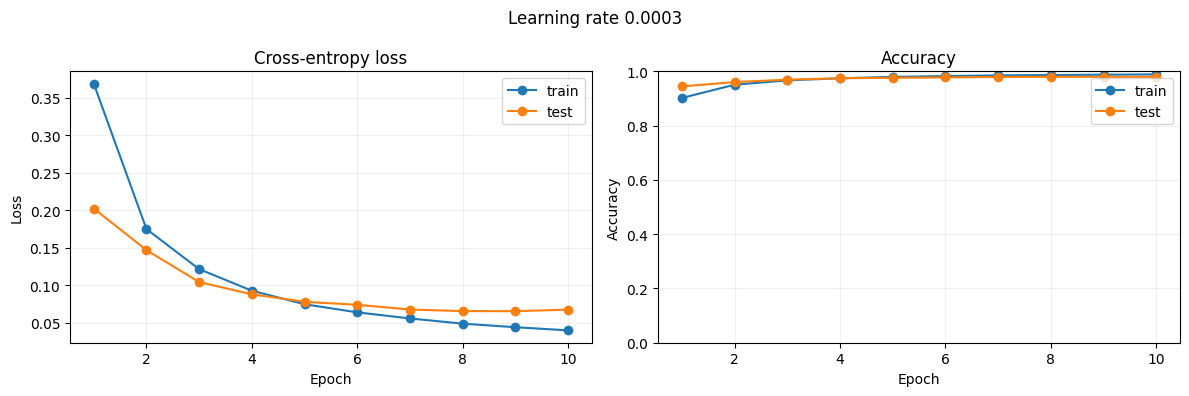

Learning rate 0.0003: final train=98.88%, test=97.94%


In [12]:
history_lr_3e4=run_experiment('Learning rate 0.0003',lr=3e-4)

Epoch 01/10: train loss=0.3803, train acc=92.41%; test loss=0.1823, test acc=94.83%; 9.8s
Epoch 02/10: train loss=0.1916, train acc=94.47%; test loss=0.2020, test acc=94.42%; 9.6s
Epoch 03/10: train loss=0.1780, train acc=94.95%; test loss=0.2051, test acc=94.51%; 9.5s
Epoch 04/10: train loss=0.1898, train acc=94.66%; test loss=0.2089, test acc=94.03%; 10.0s
Epoch 05/10: train loss=0.1777, train acc=95.06%; test loss=0.2457, test acc=94.03%; 9.4s
Epoch 06/10: train loss=0.1760, train acc=95.12%; test loss=0.2413, test acc=94.18%; 9.7s
Epoch 07/10: train loss=0.2393, train acc=94.16%; test loss=0.3095, test acc=93.28%; 9.8s
Epoch 08/10: train loss=0.1846, train acc=95.10%; test loss=0.2474, test acc=94.16%; 9.5s
Epoch 09/10: train loss=0.1629, train acc=95.50%; test loss=0.2225, test acc=94.96%; 9.8s
Epoch 10/10: train loss=0.1544, train acc=95.76%; test loss=0.2413, test acc=94.76%; 10.1s


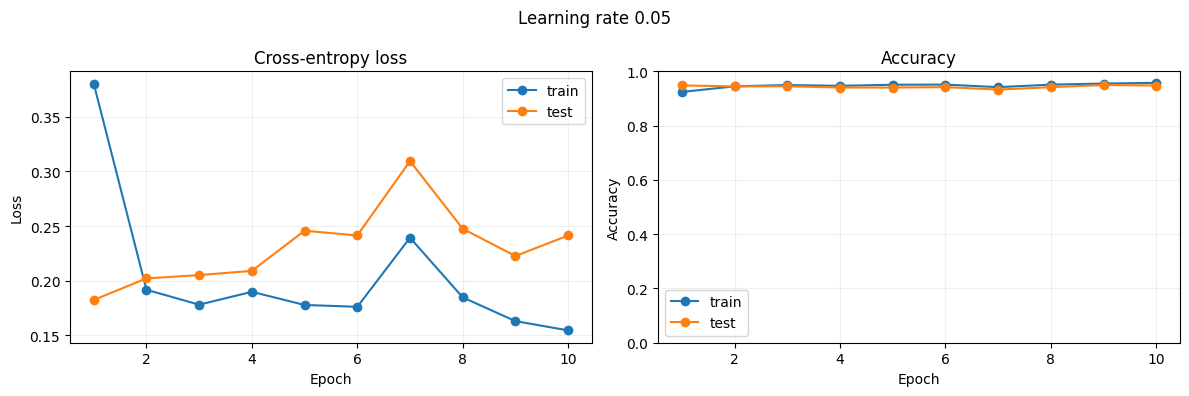

Learning rate 0.05: final train=95.76%, test=94.76%


In [13]:
history_lr_5e2=run_experiment('Learning rate 0.05',lr=5e-2)

### ❓ **Q 5.2.1 For each learning rate, explain if the model is underfitting, overfitting, or is training well. Explain the difference between high learning rates and low learning rates in terms of the optimization process.**

**Answer:** At learning rate **0.002**, test accuracy reached **97.89%** (training: **99.73%**), showing fast learning but a growing train–test gap and rising test loss late in training (**0.0638** at epoch 5 versus **0.0847** at epoch 10), suggesting some overfitting. At **0.0003**, test accuracy was **97.94%** (training: **98.88%**); improvement was steadier and the smaller gap suggests better generalization, not clear underfitting by epoch 10. At **0.05**, accuracy ended at **94.76%**, with unstable loss and weaker convergence, consistent with an overly large step size. A smaller learning rate gives more controlled updates but can require more epochs; a very high learning rate can overshoot good solutions.

---

### **5.3 Optimizer**
The optimizer we have used before is Adam. Change the optimizer to:
- **Stochastic gradient descent ([SGD](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html))**
- **SGD with momentum:** try momentum 0.5 and 0.9.

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

Epoch 01/10: train loss=0.9006, train acc=81.03%; test loss=0.4350, test acc=88.73%; 10.0s
Epoch 02/10: train loss=0.4048, train acc=88.87%; test loss=0.3487, test acc=90.17%; 9.0s
Epoch 03/10: train loss=0.3536, train acc=89.94%; test loss=0.3211, test acc=90.90%; 9.0s
Epoch 04/10: train loss=0.3313, train acc=90.44%; test loss=0.3068, test acc=91.15%; 9.1s
Epoch 05/10: train loss=0.3178, train acc=90.81%; test loss=0.2962, test acc=91.48%; 8.9s
Epoch 06/10: train loss=0.3082, train acc=91.14%; test loss=0.2911, test acc=91.72%; 9.2s
Epoch 07/10: train loss=0.3009, train acc=91.32%; test loss=0.2847, test acc=91.98%; 9.1s
Epoch 08/10: train loss=0.2949, train acc=91.58%; test loss=0.2859, test acc=92.01%; 9.0s
Epoch 09/10: train loss=0.2898, train acc=91.74%; test loss=0.2767, test acc=92.05%; 9.0s
Epoch 10/10: train loss=0.2855, train acc=91.88%; test loss=0.2725, test acc=92.30%; 9.1s


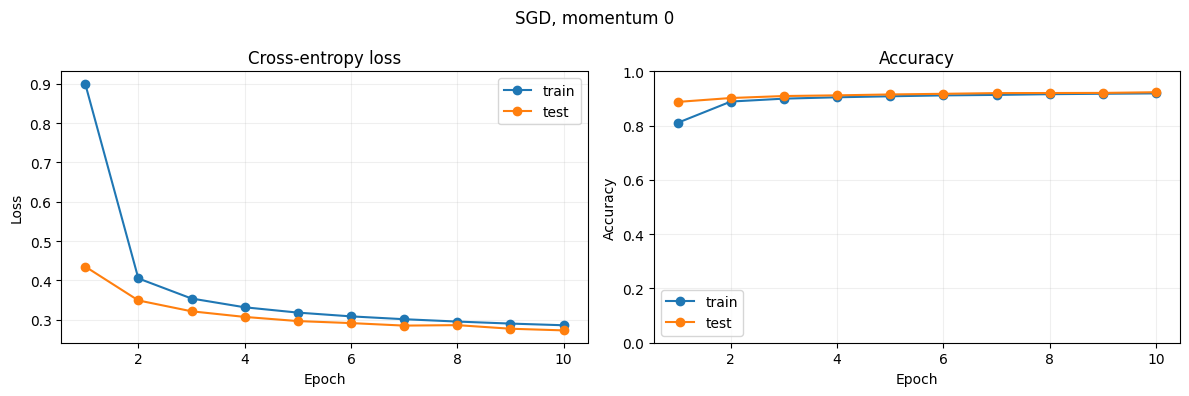

SGD, momentum 0: final train=91.88%, test=92.30%


In [14]:
history_sgd=run_experiment('SGD, momentum 0',lr=0.002,optimizer_type='sgd')

Epoch 01/10: train loss=0.6581, train acc=84.36%; test loss=0.3507, test acc=90.22%; 9.2s
Epoch 02/10: train loss=0.3457, train acc=90.05%; test loss=0.3089, test acc=91.30%; 9.7s
Epoch 03/10: train loss=0.3164, train acc=90.83%; test loss=0.2911, test acc=91.71%; 9.2s
Epoch 04/10: train loss=0.3013, train acc=91.27%; test loss=0.2825, test acc=91.82%; 9.1s
Epoch 05/10: train loss=0.2906, train acc=91.67%; test loss=0.2737, test acc=92.29%; 9.1s
Epoch 06/10: train loss=0.2827, train acc=91.94%; test loss=0.2720, test acc=92.42%; 9.1s
Epoch 07/10: train loss=0.2760, train acc=92.14%; test loss=0.2644, test acc=92.61%; 9.4s
Epoch 08/10: train loss=0.2700, train acc=92.42%; test loss=0.2632, test acc=92.62%; 9.6s
Epoch 09/10: train loss=0.2644, train acc=92.55%; test loss=0.2552, test acc=92.75%; 9.7s
Epoch 10/10: train loss=0.2593, train acc=92.73%; test loss=0.2507, test acc=92.95%; 9.7s


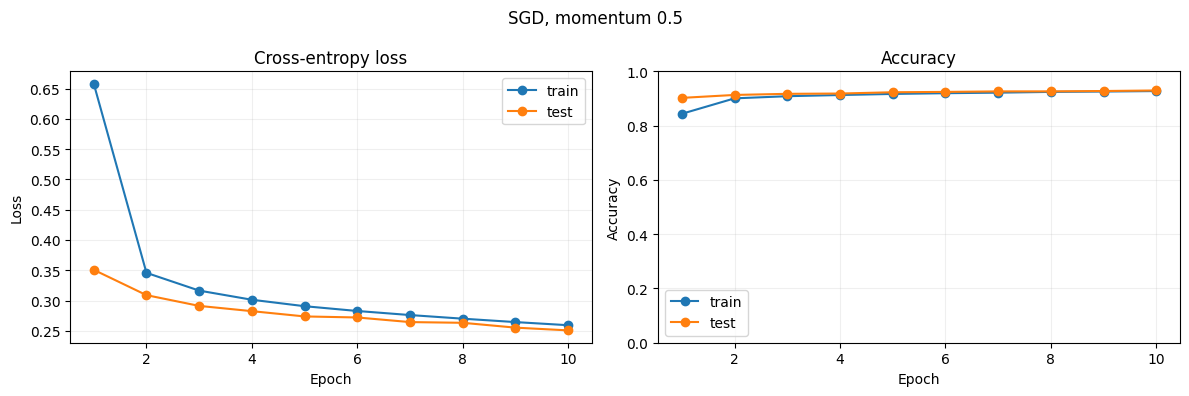

SGD, momentum 0.5: final train=92.73%, test=92.95%


In [15]:
history_sgd05=run_experiment('SGD, momentum 0.5',lr=0.002,optimizer_type='sgd',momentum=0.5)

Epoch 01/10: train loss=0.4187, train acc=88.17%; test loss=0.2865, test acc=91.90%; 9.6s
Epoch 02/10: train loss=0.2903, train acc=91.67%; test loss=0.2675, test acc=92.73%; 9.1s
Epoch 03/10: train loss=0.2599, train acc=92.59%; test loss=0.2324, test acc=93.27%; 9.1s
Epoch 04/10: train loss=0.2291, train acc=93.55%; test loss=0.2087, test acc=94.18%; 9.2s
Epoch 05/10: train loss=0.1966, train acc=94.52%; test loss=0.1747, test acc=95.23%; 9.1s
Epoch 06/10: train loss=0.1679, train acc=95.34%; test loss=0.1572, test acc=95.75%; 9.6s
Epoch 07/10: train loss=0.1439, train acc=96.06%; test loss=0.1349, test acc=96.21%; 9.6s
Epoch 08/10: train loss=0.1251, train acc=96.66%; test loss=0.1204, test acc=96.58%; 9.7s
Epoch 09/10: train loss=0.1112, train acc=96.98%; test loss=0.1082, test acc=96.96%; 9.8s
Epoch 10/10: train loss=0.1001, train acc=97.35%; test loss=0.1053, test acc=96.91%; 9.9s


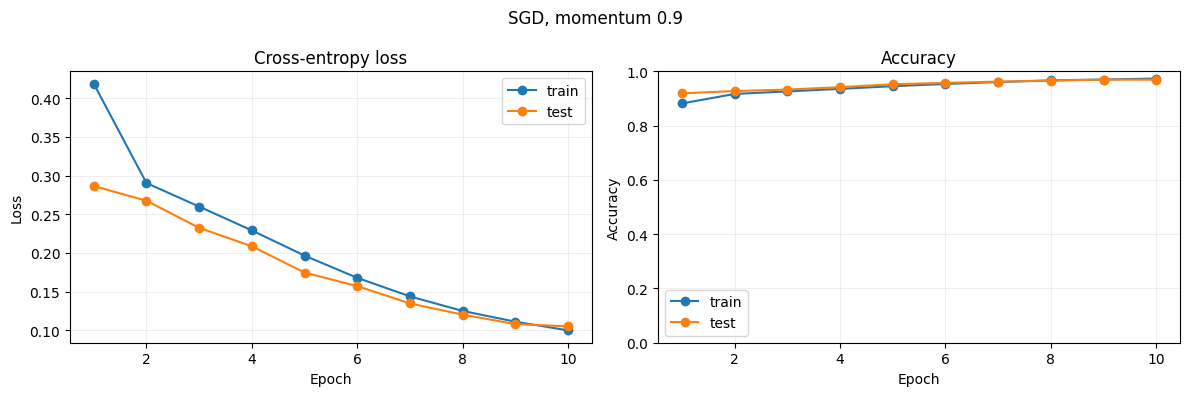

SGD, momentum 0.9: final train=97.35%, test=96.91%


In [16]:
history_sgd09=run_experiment('SGD, momentum 0.9',lr=0.002,optimizer_type='sgd',momentum=0.9)

#### ❓ **Q 5.3.1 Explain the differences in Adam and both SGD optimizations. Compare the results of each optimizer based on the learning curves.**

**Answer:** With learning rate **0.002**, **Adam** finished at **97.89%** test accuracy, exceeding SGD without momentum (**92.30%**), SGD with **0.5** momentum (**92.95%**), and SGD with **0.9** momentum (**96.91%**). Adam converged quickly by adapting updates for individual parameters. Plain SGD improved gradually, whereas momentum accumulated useful gradient directions, particularly at **0.9**, producing substantially faster improvement. For these settings and 10 epochs, **Adam performed best**, although an independently tuned SGD learning rate could change that comparison.

---

### **5.4 Initializing Weights**

Initialize the weights to:
- all zeros
- all ones
- all randomly initialized with a normal distribution.

Use 2-Layer CNN.

Epoch 01/10: train loss=2.3015, train acc=11.18%; test loss=2.3009, test acc=11.35%; 9.9s
Epoch 02/10: train loss=2.3014, train acc=11.24%; test loss=2.3011, test acc=11.35%; 9.5s
Epoch 03/10: train loss=2.3014, train acc=11.24%; test loss=2.3010, test acc=11.35%; 9.4s
Epoch 04/10: train loss=2.3013, train acc=11.24%; test loss=2.3013, test acc=11.35%; 9.5s
Epoch 05/10: train loss=2.3014, train acc=11.24%; test loss=2.3011, test acc=11.35%; 9.6s
Epoch 06/10: train loss=2.3014, train acc=11.24%; test loss=2.3010, test acc=11.35%; 9.3s
Epoch 07/10: train loss=2.3014, train acc=11.24%; test loss=2.3011, test acc=11.35%; 9.4s
Epoch 08/10: train loss=2.3014, train acc=11.24%; test loss=2.3011, test acc=11.35%; 9.5s
Epoch 09/10: train loss=2.3014, train acc=11.24%; test loss=2.3012, test acc=11.35%; 9.6s
Epoch 10/10: train loss=2.3014, train acc=11.24%; test loss=2.3013, test acc=11.35%; 9.4s


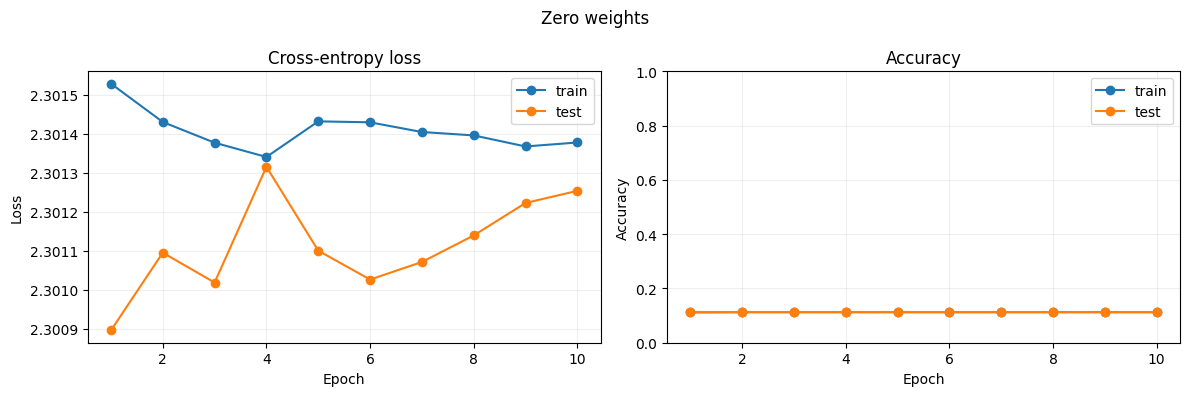

Zero weights: final train=11.24%, test=11.35%


In [17]:
history_init0=run_experiment('Zero weights',weight_init='zeros')

Epoch 01/10: train loss=1.1892, train acc=87.08%; test loss=0.3488, test acc=90.89%; 9.4s
Epoch 02/10: train loss=0.3473, train acc=90.58%; test loss=0.3188, test acc=91.62%; 9.9s
Epoch 03/10: train loss=0.3062, train acc=91.47%; test loss=0.2818, test acc=92.19%; 9.9s
Epoch 04/10: train loss=0.2870, train acc=91.98%; test loss=0.2737, test acc=92.18%; 9.9s
Epoch 05/10: train loss=0.2721, train acc=92.32%; test loss=0.2591, test acc=92.75%; 9.7s
Epoch 06/10: train loss=0.2024, train acc=94.31%; test loss=0.1438, test acc=95.92%; 9.6s
Epoch 07/10: train loss=0.1053, train acc=97.06%; test loss=0.0952, test acc=97.21%; 9.4s
Epoch 08/10: train loss=0.0702, train acc=97.92%; test loss=0.0799, test acc=97.57%; 9.3s
Epoch 09/10: train loss=0.0548, train acc=98.31%; test loss=0.0804, test acc=97.55%; 9.8s
Epoch 10/10: train loss=0.0444, train acc=98.67%; test loss=0.0788, test acc=97.64%; 9.7s


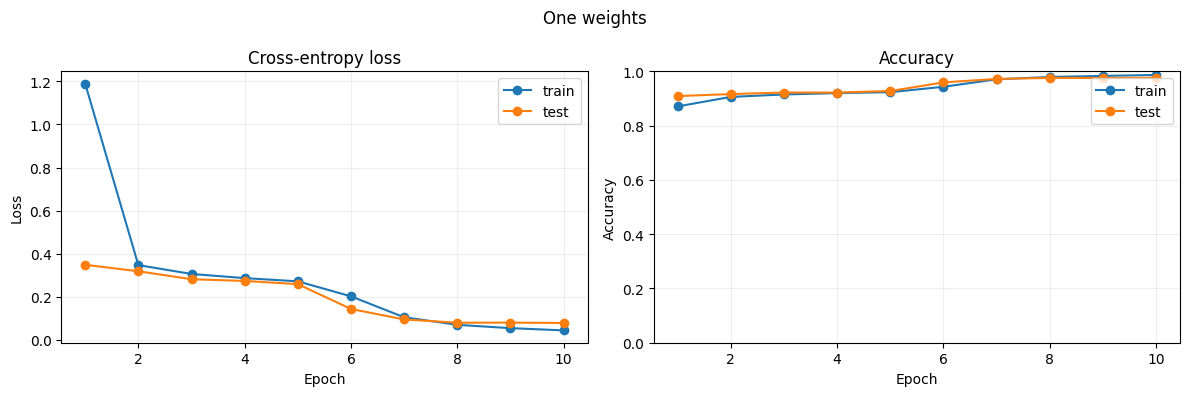

One weights: final train=98.67%, test=97.64%


In [18]:
history_init1=run_experiment('One weights',weight_init='ones')

Epoch 01/10: train loss=0.2543, train acc=92.77%; test loss=0.1127, test acc=96.64%; 10.1s
Epoch 02/10: train loss=0.0982, train acc=97.05%; test loss=0.0817, test acc=97.33%; 10.4s
Epoch 03/10: train loss=0.0679, train acc=97.96%; test loss=0.0715, test acc=97.69%; 9.9s
Epoch 04/10: train loss=0.0537, train acc=98.34%; test loss=0.0708, test acc=97.84%; 9.4s
Epoch 05/10: train loss=0.0428, train acc=98.65%; test loss=0.0660, test acc=97.92%; 9.4s
Epoch 06/10: train loss=0.0362, train acc=98.84%; test loss=0.0766, test acc=97.52%; 9.7s
Epoch 07/10: train loss=0.0304, train acc=98.99%; test loss=0.0721, test acc=97.95%; 9.4s
Epoch 08/10: train loss=0.0234, train acc=99.27%; test loss=0.0754, test acc=98.04%; 9.4s
Epoch 09/10: train loss=0.0215, train acc=99.30%; test loss=0.0739, test acc=98.00%; 9.7s
Epoch 10/10: train loss=0.0171, train acc=99.45%; test loss=0.0853, test acc=97.99%; 9.3s


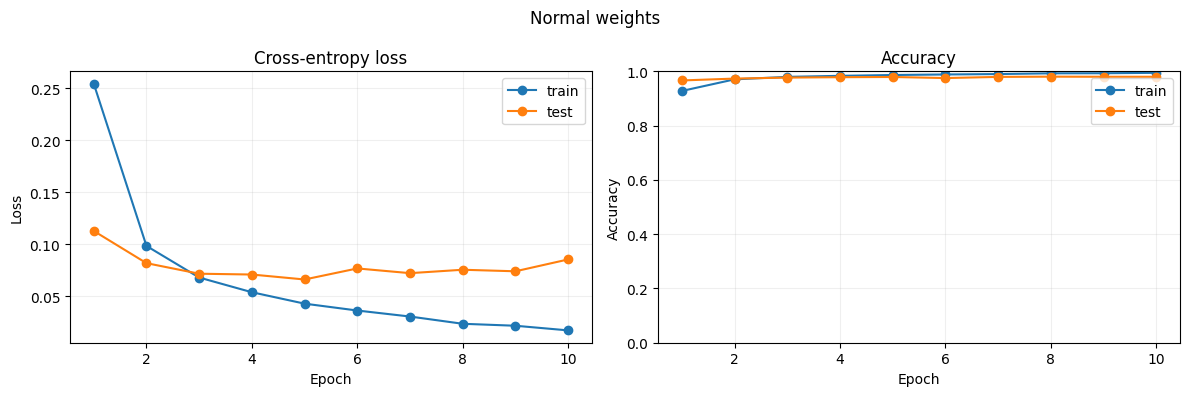

Normal weights: final train=99.45%, test=97.99%


In [19]:
history_initnormal=run_experiment('Normal weights',weight_init='normal')

#### ❓ **Q 5.4.1 How is the training process affected when we initialize our network weights differently? Based on what you observe, give a recommendation as to how weights should be initialized. Explain your reasoning.**

(Note: your results may not reflect what is expected. Please explain what is expected and why your results may not reflect that.)

**Answer:** **Zero initialization** failed to learn useful features: test accuracy remained **11.35%** with loss around **2.30**, close to guessing among ten classes. **All-one initialization** eventually reached **97.64%** but learned more slowly early on. **Normal random initialization** reached **97.99%** and produced a lower final training loss, showing the benefit of breaking symmetry and starting with reasonably sized weights. I recommend independent random initialization suited to the activation, such as **He/Kaiming for ReLU** (rather than setting every weight to the same value).

---

### **5.5 Activation Function**

Please change the `relu` function in the example code to a `tanh` function.

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

Epoch 01/10: train loss=0.3496, train acc=89.89%; test loss=0.2584, test acc=92.95%; 9.6s
Epoch 02/10: train loss=0.2587, train acc=92.52%; test loss=0.2655, test acc=92.46%; 9.4s
Epoch 03/10: train loss=0.2286, train acc=93.43%; test loss=0.2335, test acc=93.51%; 9.3s
Epoch 04/10: train loss=0.2145, train acc=93.93%; test loss=0.2242, test acc=93.47%; 9.5s
Epoch 05/10: train loss=0.1986, train acc=94.19%; test loss=0.2211, test acc=93.98%; 9.7s
Epoch 06/10: train loss=0.1889, train acc=94.57%; test loss=0.2379, test acc=93.09%; 9.6s
Epoch 07/10: train loss=0.1777, train acc=94.77%; test loss=0.2126, test acc=94.04%; 9.8s
Epoch 08/10: train loss=0.1656, train acc=95.11%; test loss=0.2143, test acc=94.00%; 9.6s
Epoch 09/10: train loss=0.1582, train acc=95.27%; test loss=0.1997, test acc=94.36%; 9.2s
Epoch 10/10: train loss=0.1474, train acc=95.65%; test loss=0.2087, test acc=94.42%; 9.4s


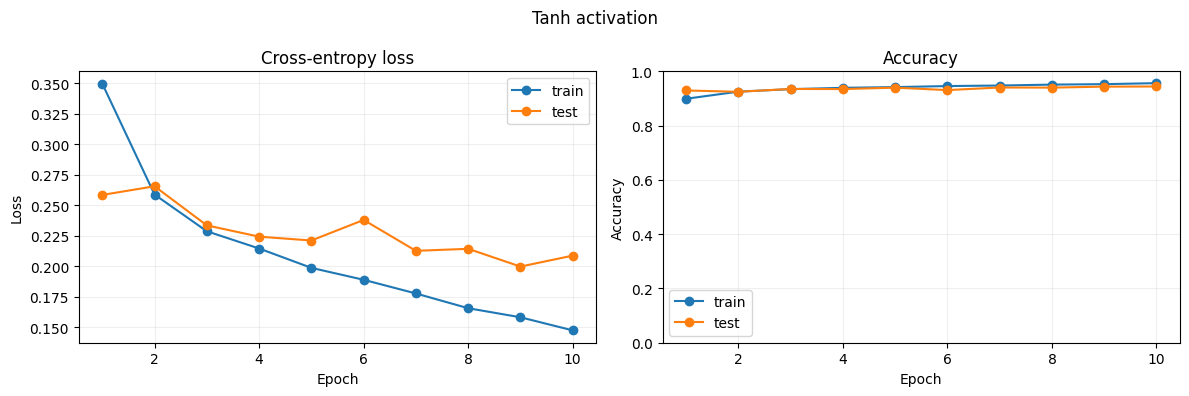

Tanh activation: final train=95.65%, test=94.42%


In [20]:
history_tanh=run_experiment('Tanh activation',model_factory=lambda: Net2(activation='tanh'))

#### ❓ **Q 5.5.1 How does changing the activation function to tanh affect the performance? Is it better or worse? Explain why.**

**Answer:** With **tanh**, the network achieved **94.42%** test accuracy after 10 epochs, compared with **97.89%** for the ReLU experiment at learning rate 0.002. Thus, **ReLU was better in this run**. ReLU avoids positive-side saturation and often supports faster gradient-based learning, whereas tanh saturates for large positive or negative inputs and can reduce gradients. This is an observation for these particular settings, not a claim that tanh always performs worse.

---

### **5.6 Batch Size**

Test training using different batch sizes to compare. Please use batch size of:
- 8
- 64
- 128

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

Epoch 01/10: train loss=0.1471, train acc=95.53%; test loss=0.0679, test acc=97.77%; 23.6s
Epoch 02/10: train loss=0.0586, train acc=98.17%; test loss=0.0685, test acc=97.92%; 24.1s
Epoch 03/10: train loss=0.0363, train acc=98.86%; test loss=0.0694, test acc=98.07%; 23.6s
Epoch 04/10: train loss=0.0217, train acc=99.28%; test loss=0.0851, test acc=98.09%; 22.7s
Epoch 05/10: train loss=0.0149, train acc=99.52%; test loss=0.0866, test acc=98.11%; 22.6s
Epoch 06/10: train loss=0.0103, train acc=99.65%; test loss=0.0890, test acc=98.11%; 22.7s
Epoch 07/10: train loss=0.0065, train acc=99.78%; test loss=0.1038, test acc=98.02%; 21.9s
Epoch 08/10: train loss=0.0060, train acc=99.78%; test loss=0.1055, test acc=98.15%; 21.9s
Epoch 09/10: train loss=0.0040, train acc=99.85%; test loss=0.1218, test acc=98.01%; 22.0s
Epoch 10/10: train loss=0.0037, train acc=99.88%; test loss=0.1256, test acc=98.03%; 22.0s


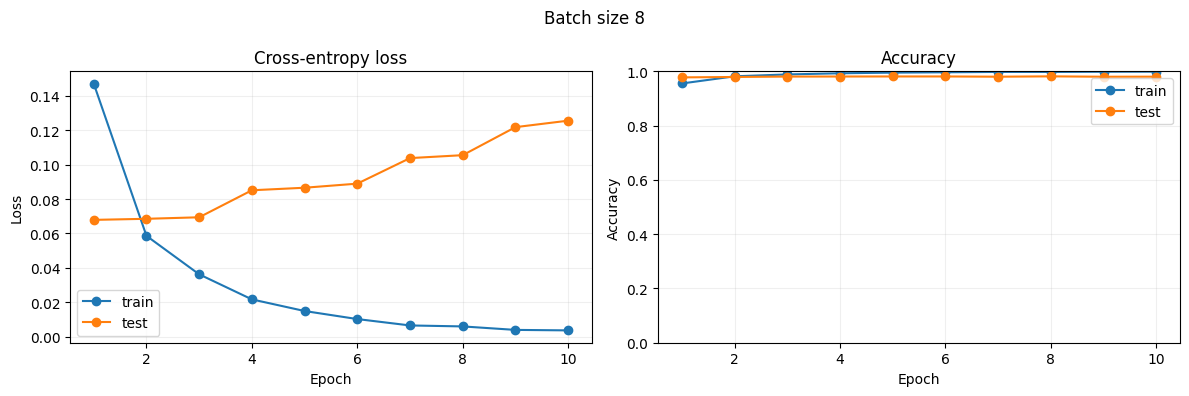

Batch size 8: final train=99.88%, test=98.03%


In [21]:
history_bs8=run_experiment('Batch size 8',batch_size_exp=8)

Epoch 01/10: train loss=0.2003, train acc=94.15%; test loss=0.0855, test acc=97.38%; 8.6s
Epoch 02/10: train loss=0.0727, train acc=97.80%; test loss=0.0708, test acc=97.72%; 8.6s
Epoch 03/10: train loss=0.0501, train acc=98.44%; test loss=0.0664, test acc=97.98%; 8.7s
Epoch 04/10: train loss=0.0378, train acc=98.80%; test loss=0.0689, test acc=98.02%; 9.0s
Epoch 05/10: train loss=0.0270, train acc=99.14%; test loss=0.0637, test acc=98.03%; 8.9s
Epoch 06/10: train loss=0.0229, train acc=99.27%; test loss=0.0781, test acc=97.67%; 8.9s
Epoch 07/10: train loss=0.0171, train acc=99.45%; test loss=0.0753, test acc=98.05%; 8.8s
Epoch 08/10: train loss=0.0115, train acc=99.67%; test loss=0.0757, test acc=97.98%; 8.9s
Epoch 09/10: train loss=0.0105, train acc=99.66%; test loss=0.0817, test acc=98.05%; 8.9s
Epoch 10/10: train loss=0.0083, train acc=99.74%; test loss=0.0873, test acc=97.88%; 8.9s


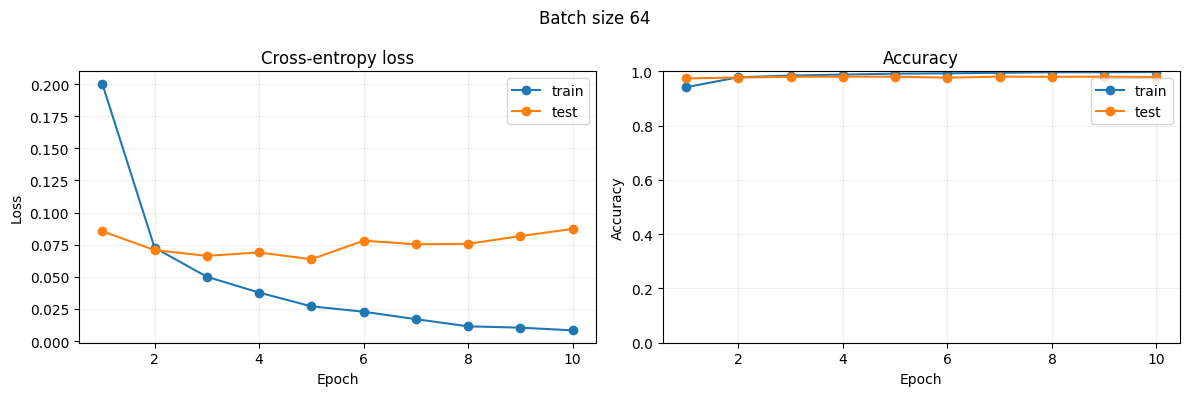

Batch size 64: final train=99.74%, test=97.88%


In [22]:
history_bs64=run_experiment('Batch size 64',batch_size_exp=64)

Epoch 01/10: train loss=0.2445, train acc=92.80%; test loss=0.0989, test acc=97.07%; 8.3s
Epoch 02/10: train loss=0.0834, train acc=97.54%; test loss=0.0739, test acc=97.62%; 8.1s
Epoch 03/10: train loss=0.0584, train acc=98.22%; test loss=0.0665, test acc=97.83%; 8.0s
Epoch 04/10: train loss=0.0454, train acc=98.59%; test loss=0.0736, test acc=97.70%; 8.0s
Epoch 05/10: train loss=0.0350, train acc=98.91%; test loss=0.0641, test acc=97.94%; 7.9s
Epoch 06/10: train loss=0.0291, train acc=99.10%; test loss=0.0720, test acc=97.79%; 7.8s
Epoch 07/10: train loss=0.0229, train acc=99.29%; test loss=0.0647, test acc=98.18%; 7.9s
Epoch 08/10: train loss=0.0185, train acc=99.48%; test loss=0.0677, test acc=98.18%; 7.8s
Epoch 09/10: train loss=0.0149, train acc=99.54%; test loss=0.0736, test acc=97.91%; 7.9s
Epoch 10/10: train loss=0.0122, train acc=99.65%; test loss=0.0738, test acc=97.96%; 7.9s


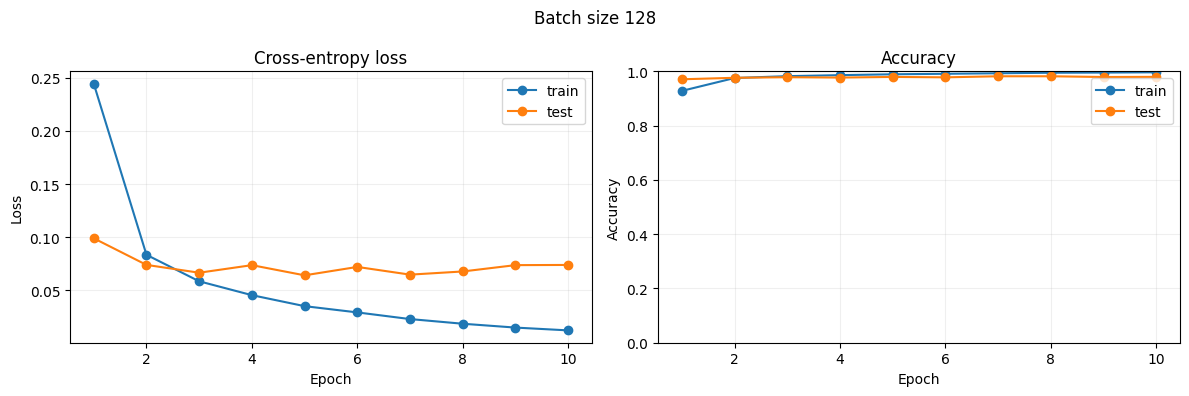

Batch size 128: final train=99.65%, test=97.96%


In [23]:
history_bs128=run_experiment('Batch size 128',batch_size_exp=128)

#### ❓ **Q 5.6.1 How does changing batch size affect the training process?**

**Answer:** At batch size **8**, final test accuracy was **98.03%**, versus **97.88%** at **64** and **97.96%** at **128**. Batch 8 gave the highest final accuracy by a small margin, but its epochs took roughly **22–24 seconds**, compared with about **9 seconds** for batch 64 and **8 seconds** for batch 128. Smaller batches make noisier, more frequent parameter updates and cost more time per epoch; larger batches are faster per epoch in this experiment but make fewer updates. **64 or 128** is more efficient if runtime matters, while **8** slightly won on final accuracy here.

---

### 5.7 Different Network Architectures

Please complete the `Net5` and `FCN` definitions. The archtiectures are defined below.


#### **5.7.1 Net5: 5-Layer CNN**
Similar to the 2-Layer model, make a new class ```Net5```.

* ***Layer 1 (Input)***: Convolutional, input channel = 1, output channel = 32, kernel size = 5, stride = 1, padding = 2.
* ***Layer 2 (Hidden 1)***: Pooling, kernel size = 2, stride = 2.
* ***Layer 3 (Hidden 2)***: Convolutional, input channel = < you find out> , output channel = 64, kernel size = 5, stride = 1 padding = 2.
* ***Layer 4 (Hidden 3)***: Fully connected, input channel = < you find out>, output channel = 1024.
* ***Layer 5 (Output)***: Fully connected, input channel = < you find out>, < you find out >

In [24]:
class Net5(nn.Module):
    def __init__(self,num_classes=10):
        super().__init__()
        self.conv1=nn.Conv2d(1,32,5,stride=1,padding=2)
        self.pool=nn.MaxPool2d(2,2)
        self.conv2=nn.Conv2d(32,64,5,stride=1,padding=2)
        self.fc1=nn.Linear(64*14*14,1024)
        self.fc2=nn.Linear(1024,num_classes)
        self.relu=nn.ReLU()
    def forward(self,x):
        x=self.pool(self.relu(self.conv1(x)))
        x=self.relu(self.conv2(x))
        x=torch.flatten(x,1)
        return self.fc2(self.relu(self.fc1(x)))

#### **5.7.2 FCN**

Here we will define a Fully Connected Network `FCN` (Not a CNN).

- **Layer 1 (Input):** Size = < you find out >
- **Layer 2 (Hidden 1):** 256 neurons
- **Layer 3 (Hidden 2):** 256 neurons
- **Layer 4 (Output):** Size = < you find out >

In [25]:
class FCN(nn.Module):
    def __init__(self,num_classes=10):
        super().__init__()
        self.layers=nn.Sequential(nn.Flatten(),nn.Linear(784,256),nn.ReLU(),
                                  nn.Linear(256,256),nn.ReLU(),nn.Linear(256,num_classes))
    def forward(self,x):return self.layers(x)

#### **5.7.3 Training the different architectures**

Train and evaluate `Net2`, `Net5`, and `FCN` using batch size of 64, the best learning rate from Section 5.1, and the best optimizer from Section 5.5


Epoch 01/10: train loss=0.2003, train acc=94.15%; test loss=0.0855, test acc=97.38%; 8.9s
Epoch 02/10: train loss=0.0727, train acc=97.80%; test loss=0.0708, test acc=97.70%; 8.8s
Epoch 03/10: train loss=0.0501, train acc=98.45%; test loss=0.0663, test acc=98.01%; 9.0s
Epoch 04/10: train loss=0.0377, train acc=98.80%; test loss=0.0688, test acc=98.02%; 8.7s
Epoch 05/10: train loss=0.0270, train acc=99.14%; test loss=0.0638, test acc=98.02%; 9.0s
Epoch 06/10: train loss=0.0229, train acc=99.26%; test loss=0.0780, test acc=97.64%; 9.0s
Epoch 07/10: train loss=0.0170, train acc=99.46%; test loss=0.0755, test acc=98.06%; 8.8s
Epoch 08/10: train loss=0.0115, train acc=99.66%; test loss=0.0755, test acc=97.95%; 8.7s
Epoch 09/10: train loss=0.0103, train acc=99.67%; test loss=0.0820, test acc=98.04%; 8.8s
Epoch 10/10: train loss=0.0082, train acc=99.74%; test loss=0.0812, test acc=98.12%; 8.7s


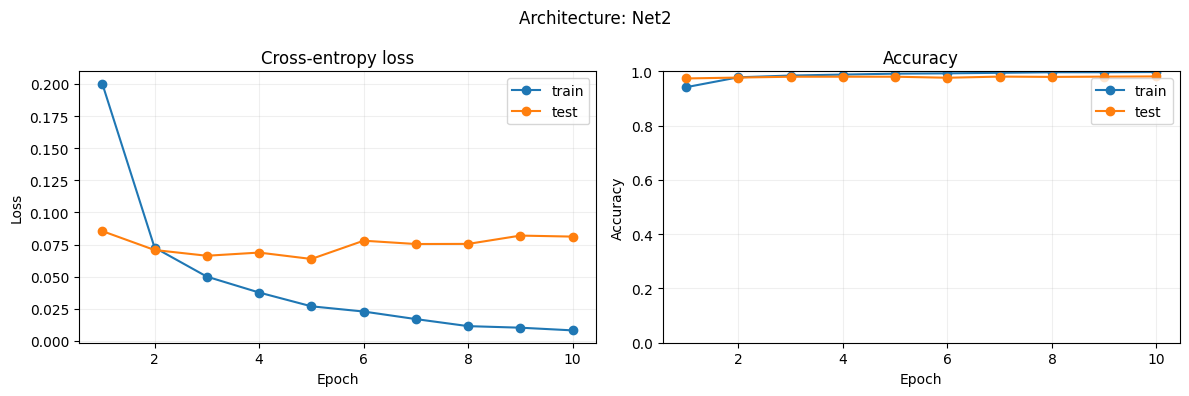

Architecture: Net2: final train=99.74%, test=98.12%


In [26]:
history_arch_net2=run_experiment('Architecture: Net2',model_factory=Net2,batch_size_exp=64)

Epoch 01/10: train loss=0.1269, train acc=96.05%; test loss=0.0422, test acc=98.59%; 14.5s
Epoch 02/10: train loss=0.0386, train acc=98.83%; test loss=0.0436, test acc=98.66%; 14.6s
Epoch 03/10: train loss=0.0283, train acc=99.09%; test loss=0.0302, test acc=99.08%; 14.4s
Epoch 04/10: train loss=0.0194, train acc=99.36%; test loss=0.0467, test acc=98.86%; 14.5s
Epoch 05/10: train loss=0.0167, train acc=99.48%; test loss=0.0414, test acc=98.70%; 14.5s
Epoch 06/10: train loss=0.0138, train acc=99.59%; test loss=0.0411, test acc=98.71%; 14.4s
Epoch 07/10: train loss=0.0097, train acc=99.70%; test loss=0.0472, test acc=98.80%; 14.5s
Epoch 08/10: train loss=0.0137, train acc=99.61%; test loss=0.0684, test acc=98.43%; 14.4s
Epoch 09/10: train loss=0.0096, train acc=99.75%; test loss=0.0461, test acc=98.93%; 14.4s
Epoch 10/10: train loss=0.0114, train acc=99.66%; test loss=0.0589, test acc=99.01%; 14.4s


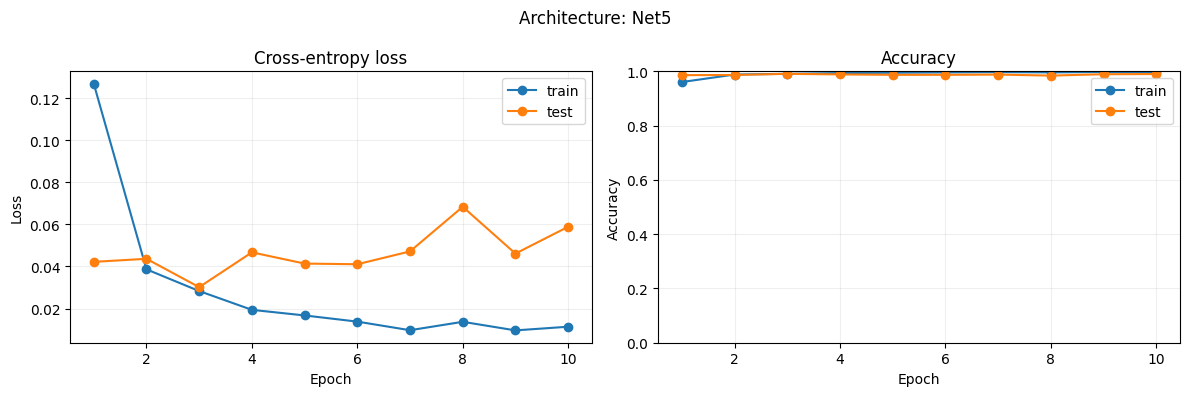

Architecture: Net5: final train=99.66%, test=99.01%


In [27]:
history_arch_net5=run_experiment('Architecture: Net5',model_factory=Net5,batch_size_exp=64)

Epoch 01/10: train loss=0.2245, train acc=93.19%; test loss=0.1229, test acc=96.09%; 9.0s
Epoch 02/10: train loss=0.0901, train acc=97.21%; test loss=0.0900, test acc=97.16%; 9.4s
Epoch 03/10: train loss=0.0641, train acc=97.97%; test loss=0.0821, test acc=97.60%; 9.0s
Epoch 04/10: train loss=0.0514, train acc=98.38%; test loss=0.0911, test acc=97.51%; 8.9s
Epoch 05/10: train loss=0.0401, train acc=98.71%; test loss=0.0814, test acc=97.69%; 9.0s
Epoch 06/10: train loss=0.0336, train acc=98.94%; test loss=0.0915, test acc=97.57%; 8.9s
Epoch 07/10: train loss=0.0319, train acc=99.04%; test loss=0.0972, test acc=97.48%; 8.9s
Epoch 08/10: train loss=0.0271, train acc=99.16%; test loss=0.0863, test acc=97.99%; 8.9s
Epoch 09/10: train loss=0.0246, train acc=99.21%; test loss=0.1143, test acc=97.30%; 9.1s
Epoch 10/10: train loss=0.0194, train acc=99.39%; test loss=0.1220, test acc=97.52%; 9.0s


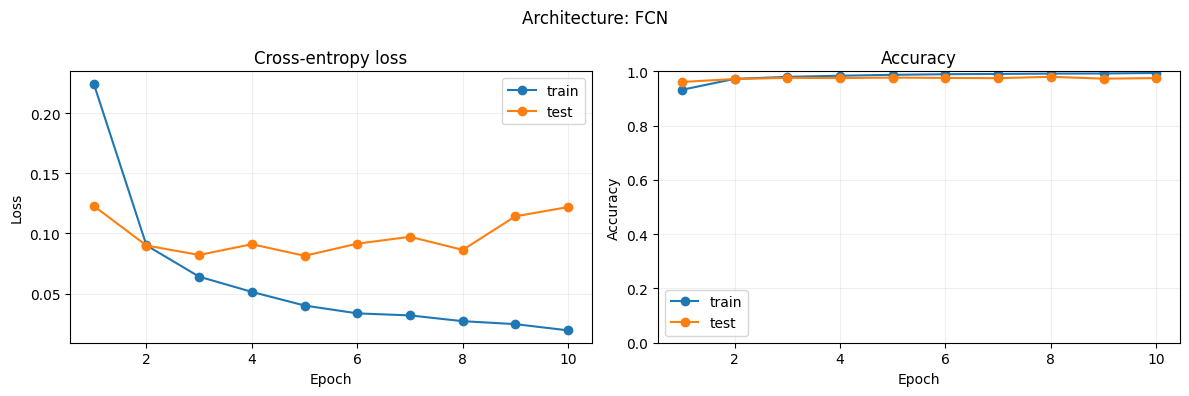

Architecture: FCN: final train=99.39%, test=97.52%


In [28]:
history_arch_fcn=run_experiment('Architecture: FCN',model_factory=FCN,batch_size_exp=64)

#### ❓ **Q 5.7.4 Explain which model is better and why. Use your learning curves as well as what you know about model capacity to explain your reasoning.** If you think your results do not reflect the best model, explain which you expect to be best and why.

**Answer:** **Net5 was the best of the three tested architectures**: final test accuracy was **99.01%**, compared with **98.12%** for Net2 and **97.52%** for the FCN. Net5's additional convolutional feature extraction and greater representational capacity helped it recognize digit patterns better. CNNs preserve local spatial structure through shared filters, whereas the FCN flattens the image before learning. Net5 also required more time per epoch and its test loss increased after its early minimum, so higher capacity comes with computational cost and some overfitting risk.

#### ❓ **Q 5.7.5 Which model converges to a minimum faster? Why? What hyperparameters would you tune in order to get a model to converge faster?**

**Answer:** **Net5 reached strong validation performance fastest in terms of epochs**, attaining **99.08%** test accuracy and **0.0302** test loss at epoch 3; Net2 and the FCN took longer to reach their best observed results. However, Net5 took about **14–15 seconds per epoch** versus roughly **9 seconds** for Net2 and the FCN, so fastest in epochs is not necessarily fastest in wall-clock time. To improve convergence, I would tune the learning rate and optimizer, use an appropriate learning-rate schedule, suitable initialization and batch normalization, and compare batch sizes while monitoring validation loss.

#### ❓ **Q 5.7.6 Explain the purpose of the pooling layer**

**Answer:** Pooling down-samples feature maps, reducing spatial resolution, parameters/computation in subsequent layers, and sensitivity to small translations. Max-pooling retains the strongest local activation. Too much pooling can discard important location detail.

#### ❓ **Q 5.7.7  Is it possible for a model to have a smaller final loss, even if it has worse test accuracy.**

**Answer:** Yes. Cross-entropy depends on the full predicted probability assigned to each class, whereas accuracy counts only whether the top-scoring class is correct. A model can be more confident on many correct examples and achieve lower loss while making a few more top-1 mistakes.

#### ❓ **Q 5.7.8 Explain the difference between the CNN models and FCN.**

**Answer:** CNNs reuse local filters across pixel locations, exploit local spatial structure and share weights, making them relatively translation-friendly. An FCN flattens the image and learns independent dense pixel interactions, usually with less spatial inductive bias. CNNs are therefore often more efficient for images.


---



### **5.8 Batch Normalization**

Choose the model that performs the best (`Net`, `Net2`, `Net5`, `FCN`). Add batch normalization layers where you see fit. Repeat and train and plot learning curves.



Epoch 01/10: train loss=0.0893, train acc=97.19%; test loss=0.0375, test acc=98.78%; 15.0s
Epoch 02/10: train loss=0.0404, train acc=98.75%; test loss=0.0408, test acc=98.62%; 14.9s
Epoch 03/10: train loss=0.0313, train acc=99.00%; test loss=0.0381, test acc=98.91%; 14.9s
Epoch 04/10: train loss=0.0225, train acc=99.27%; test loss=0.0298, test acc=99.19%; 14.8s
Epoch 05/10: train loss=0.0189, train acc=99.40%; test loss=0.0365, test acc=98.95%; 14.7s
Epoch 06/10: train loss=0.0169, train acc=99.46%; test loss=0.0516, test acc=98.51%; 14.7s
Epoch 07/10: train loss=0.0154, train acc=99.48%; test loss=0.0258, test acc=99.36%; 14.8s
Epoch 08/10: train loss=0.0111, train acc=99.63%; test loss=0.0440, test acc=98.83%; 14.8s
Epoch 09/10: train loss=0.0121, train acc=99.61%; test loss=0.0319, test acc=99.12%; 14.8s
Epoch 10/10: train loss=0.0111, train acc=99.66%; test loss=0.0340, test acc=99.19%; 14.8s


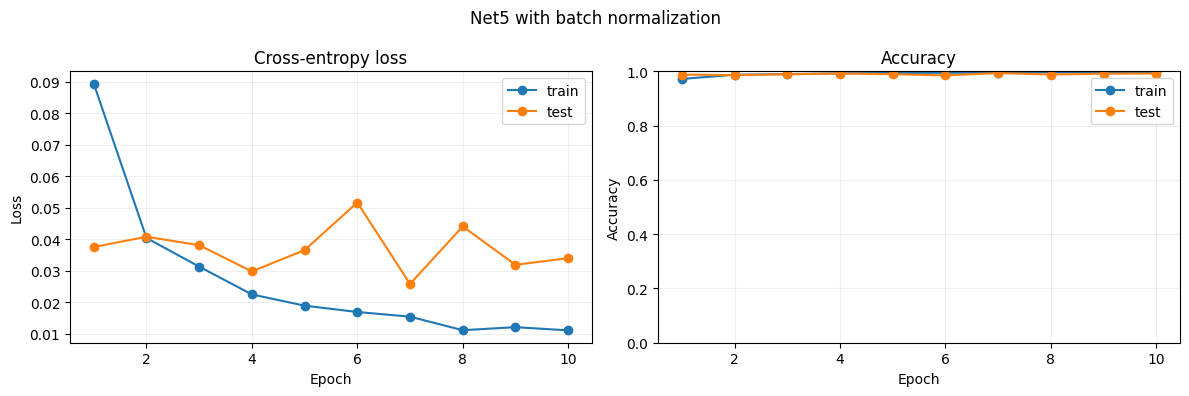

Net5 with batch normalization: final train=99.66%, test=99.19%
Compare Net5 test accuracy: 0.9901 vs normalized Net5: 0.9919


In [29]:
class Net5BN(nn.Module):
    def __init__(self,num_classes=10):
        super().__init__()
        self.features=nn.Sequential(nn.Conv2d(1,32,5,padding=2),nn.BatchNorm2d(32),nn.ReLU(),
                                    nn.MaxPool2d(2),nn.Conv2d(32,64,5,padding=2),
                                    nn.BatchNorm2d(64),nn.ReLU())
        self.classifier=nn.Sequential(nn.Flatten(),nn.Linear(64*14*14,1024),
                                      nn.BatchNorm1d(1024),nn.ReLU(),nn.Linear(1024,num_classes))
    def forward(self,x):return self.classifier(self.features(x))
history_bn=run_experiment('Net5 with batch normalization',model_factory=Net5BN,batch_size_exp=64)
print('Compare Net5 test accuracy:',history_arch_net5['test_acc'][-1],
      'vs normalized Net5:',history_bn['test_acc'][-1])

#### ❓ **Q 5.8 Explain the purpose of the batch normalization layers,and how they affect training.**

**Answer:** Batch normalization standardizes intermediate activations during training and learns scaling/shifting parameters. It can make optimization more stable and sometimes improve generalization. In this experiment, **Net5 without batch normalization** ended at **99.01%** test accuracy (test loss **0.0589**), while **Net5 with batch normalization** ended at **99.19%** (test loss **0.0340**). The normalized model also achieved its best observed test accuracy of **99.36%** at epoch 7. The final improvement of **0.18 percentage points** suggests a small benefit here, although single-run variation means it is not guaranteed in every run.

---
---

# End of Phase 1 😊🥳